# Enriched Data Visualization

## Purpose
Explore delivery labels, price and product features, holidays,
and weather before purchase.

## Data rules
- Use one timezone scenario at a time.
- Calculate late rates using valid delivery labels only.
- Report sample sizes and missing values.
- Keep source datasets unchanged.
- Interpret findings as descriptive associations.

## Saved outputs
Run all cells from the project root or notebooks folder. Tables and figures are saved under outputs/tables/enriched_eda/SCENARIO and outputs/figures/enriched_eda/SCENARIO.
CSV exports retain full precision. Multi-level columns are flattened for easier reading. Existing source datasets are not modified.


In [1]:
# Purpose: Load the merged dataset and prepare output folders.

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()

if not (ROOT / "data" / "processed").is_dir():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed"
SCENARIO = "assume_utc"

input_path = (
    DATA_DIR
    / f"research_data_weather_price_holiday_{SCENARIO}.csv"
)

df = pd.read_csv(
    input_path,
    dtype={"order_id": "string"}
)

FIGURE_DIR = (
    ROOT / "outputs" / "figures" / "enriched_eda" / SCENARIO
)

TABLE_DIR = (
    ROOT / "outputs" / "tables" / "enriched_eda" / SCENARIO
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("Loaded:", input_path.name)
print("Dataset shape:", df.shape)
# Purpose: Export readable CSV tables and PNG figures.
def save_table(table, filename, include_index=True):
    output = table.copy()
    if isinstance(output.columns, pd.MultiIndex):
        output.columns = ["_".join(map(str, values)) for values in output.columns]
    output.to_csv(TABLE_DIR / filename, index=include_index, encoding="utf-8-sig")


def save_figure(figure, filename):
    figure.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")


Loaded: research_data_weather_price_holiday_assume_utc.csv
Dataset shape: (99441, 74)


In [2]:
# Purpose: Validate order IDs and define the labelled analysis sample.

assert df["order_id"].notna().all()
assert df["order_id"].is_unique

assert df["is_late"].dropna().isin([0, 1]).all()

labelled = df.loc[
    df["is_late"].isin([0, 1])
].copy()

labelled["delivery_label"] = labelled["is_late"].map({
    0: "Not Late",
    1: "Late"
})

sample_summary = pd.DataFrame({
    "sample": [
        "All orders",
        "Valid delivery labels",
        "Missing delivery labels"
    ],
    "orders": [
        len(df),
        len(labelled),
        df["is_late"].isna().sum()
    ]
})

display(sample_summary)

sample_summary.to_csv(
    TABLE_DIR / "vis00_sample_summary.csv",
    index=False
)

,sample,orders
0,All orders,99441
1,Valid delivery labels,96470
2,Missing delivery labels,2971


,delivery_label,orders,percent
0,Not Late,89936,93.22691
1,Late,6534,6.77309


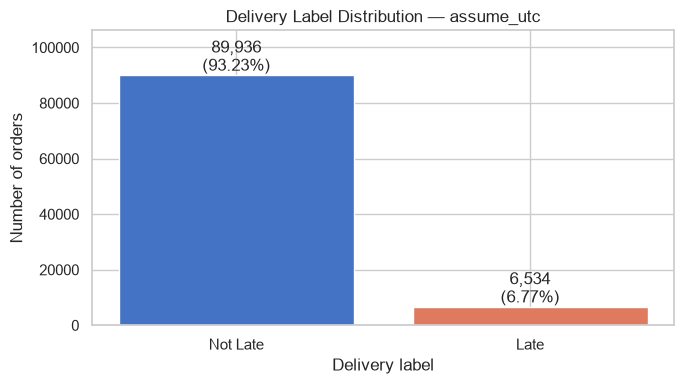

In [3]:
# Purpose: Plot the number and percentage of each delivery label.

label_summary = (
    labelled["delivery_label"]
    .value_counts()
    .reindex(["Not Late", "Late"])
    .rename_axis("delivery_label")
    .reset_index(name="orders")
)

label_summary["percent"] = (
    label_summary["orders"] / len(labelled) * 100
)

display(label_summary)

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    label_summary["delivery_label"],
    label_summary["orders"],
    color=["#4472C4", "#E07A5F"]
)

for position, row in label_summary.iterrows():
    ax.text(
        position,
        row["orders"],
        f"{row['orders']:,.0f}\n({row['percent']:.2f}%)",
        ha="center",
        va="bottom"
    )

ax.set(
    title=f"Delivery Label Distribution — {SCENARIO}",
    xlabel="Delivery label",
    ylabel="Number of orders"
)

ax.margins(y=0.18)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "vis01_delivery_labels.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

label_summary.to_csv(
    TABLE_DIR / "vis01_delivery_labels.csv",
    index=False
)

In [4]:
# Purpose: Summarise missing additional features in labelled orders.

price_product_features = [
    "order_total_value",
    "freight_to_items_ratio",
    "mean_item_value",
    "freight_per_item",
    "total_product_weight_g",
    "total_product_volume_cm3",
    "product_category_count",
    "weight_coverage_ratio",
    "volume_coverage_ratio",
    "category_coverage_ratio"
]

holiday_features = [
    "purchase_is_national_holiday",
    "days_to_next_national_holiday",
    "national_holiday_count_in_estimated_window"
]

weather_features = [
    column for column in df.columns
    if column.startswith(("destination_", "origin_"))
]

additional_features = (
    price_product_features
    + holiday_features
    + weather_features
)

missing_columns = [
    column for column in additional_features
    if column not in labelled.columns
]

assert not missing_columns, f"Missing columns: {missing_columns}"

missing_summary = pd.DataFrame({
    "missing_rows": labelled[additional_features].isna().sum(),
    "missing_percent": (
        labelled[additional_features].isna().mean() * 100
    )
})

missing_summary.index.name = "feature"

missing_summary = (
    missing_summary.reset_index()
    .sort_values("missing_percent", ascending=False)
)

display(missing_summary.round(3))

missing_summary.to_csv(
    TABLE_DIR / "vis02_missing_features.csv",
    index=False
)

,feature,missing_rows,missing_percent
6,product_category_count,1392,1.443
13,destination_rain_state_mean_mm,926,0.960
17,destination_humidity_state_mean_pct,770,0.798
19,destination_wind_gust_max_station_mean_ms,673,0.698
18,destination_wind_speed_sample_state_mean_ms,652,0.676
16,destination_air_temp_min_station_mean_c,612,0.634
15,destination_air_temp_max_station_mean_c,605,0.627
14,destination_air_temp_state_mean_c,586,0.607
21,origin_rain_state_mean_mm,159,0.165
29,origin_humidity_state_mean_pct,153,0.159


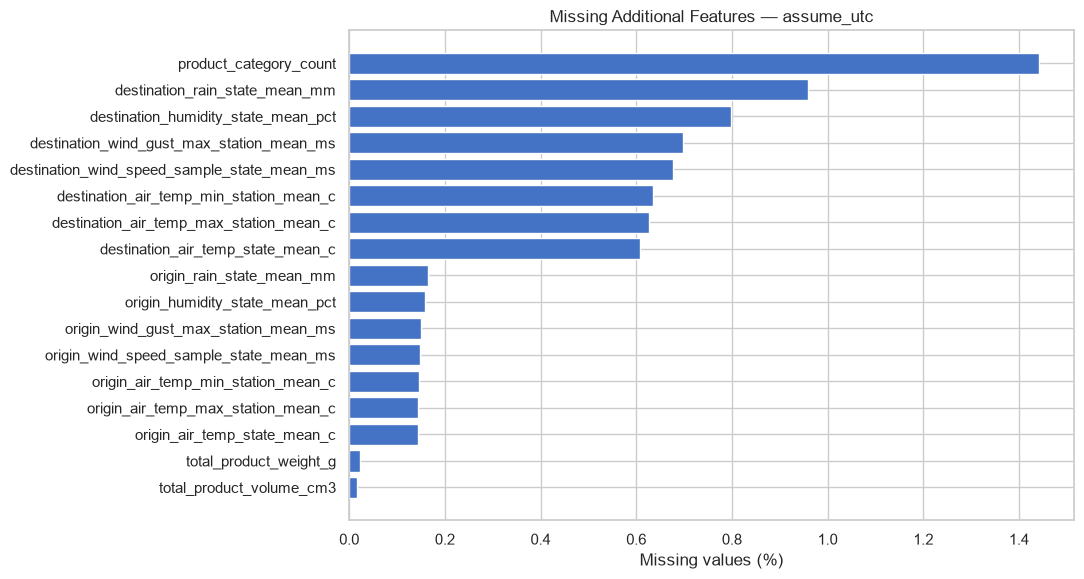

In [5]:
# Purpose: Plot features with missing values in the labelled sample.

plot_data = (
    missing_summary.loc[
        missing_summary["missing_rows"] > 0
    ]
    .sort_values("missing_percent", ascending=True)
)

if plot_data.empty:
    print("No missing values in the selected features.")

else:
    fig, ax = plt.subplots(
        figsize=(11, max(4, len(plot_data) * 0.35))
    )

    ax.barh(
        plot_data["feature"],
        plot_data["missing_percent"],
        color="#4472C4"
    )

    ax.set(
        title=f"Missing Additional Features — {SCENARIO}",
        xlabel="Missing values (%)",
        ylabel=""
    )

    fig.tight_layout()
    fig.savefig(
        FIGURE_DIR / "vis02_missing_features.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [6]:
# Purpose: Validate order IDs and select valid delivery labels.

assert df["order_id"].notna().all()
assert df["order_id"].is_unique
assert df["is_late"].dropna().isin([0, 1]).all()

labelled = df.loc[
    df["is_late"].isin([0, 1])
].copy()

labelled["delivery_label"] = labelled["is_late"].map({
    0: "Not Late",
    1: "Late"
})

summary = pd.DataFrame({
    "sample": [
        "All orders",
        "Valid labels",
        "Late",
        "Not Late",
        "Missing labels"
    ],
    "orders": [
        len(df),
        len(labelled),
        labelled["is_late"].eq(1).sum(),
        labelled["is_late"].eq(0).sum(),
        df["is_late"].isna().sum()
    ]
})

display(summary)
save_table(summary, "vis00_detailed_sample_summary.csv", False)


,sample,orders
0,All orders,99441
1,Valid labels,96470
2,Late,6534
3,Not Late,89936
4,Missing labels,2971


,orders,percent
delivery_label,,
Not Late,89936,93.23
Late,6534,6.77


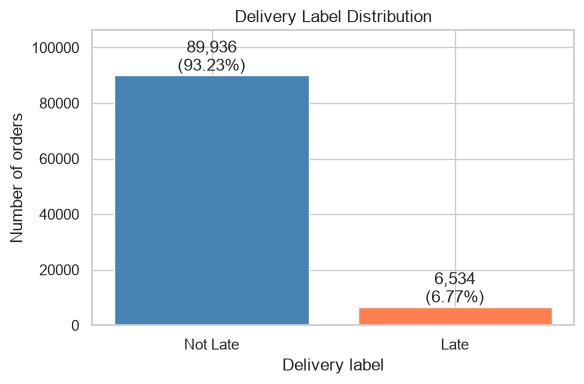

In [7]:
# Purpose: Display the delivery label distribution.

counts = (
    labelled["delivery_label"]
    .value_counts()
    .reindex(["Not Late", "Late"], fill_value=0)
)

percent = counts / counts.sum() * 100

display(pd.DataFrame({
    "orders": counts,
    "percent": percent.round(2)
}))

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(
    counts.index,
    counts.values,
    color=["steelblue", "coral"]
)

for position, label in enumerate(counts.index):
    ax.text(
        position,
        counts[label],
        f"{counts[label]:,}\n({percent[label]:.2f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title("Delivery Label Distribution")
ax.set_xlabel("Delivery label")
ax.set_ylabel("Number of orders")
ax.margins(y=0.18)

plt.tight_layout()
save_figure(plt.gcf(), "vis01_label_distribution_detail.png")
plt.show()
save_table(pd.DataFrame({"orders": counts, "percent": percent}), "vis01_label_distribution_detail.csv")


,valid_orders,late_orders,late_rate_percent
purchase_is_national_holiday,,,
Non-holiday,94993,6462.0,6.80
Holiday,1477,72.0,4.87


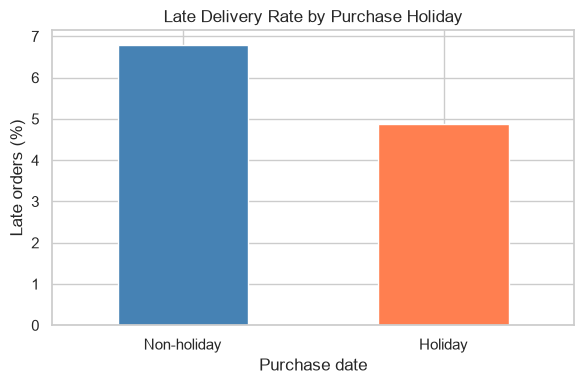

Labelled orders without a valid holiday flag: 0


In [8]:
# Purpose: Compare late rates by purchase holiday status.

holiday_data = labelled.loc[
    labelled["purchase_is_national_holiday"].isin([0, 1])
]

holiday_summary = (
    holiday_data.groupby("purchase_is_national_holiday")
    .agg(
        valid_orders=("is_late", "size"),
        late_orders=("is_late", "sum")
    )
    .rename(index={0: "Non-holiday", 1: "Holiday"})
)

holiday_summary["late_rate_percent"] = (
    holiday_summary["late_orders"]
    / holiday_summary["valid_orders"] * 100
)

display(holiday_summary.round(2))

ax = holiday_summary["late_rate_percent"].plot(
    kind="bar",
    color=["steelblue", "coral"],
    figsize=(6, 4),
    rot=0
)

ax.set_title("Late Delivery Rate by Purchase Holiday")
ax.set_xlabel("Purchase date")
ax.set_ylabel("Late orders (%)")

plt.tight_layout()
save_figure(plt.gcf(), "vis03_purchase_holiday.png")
plt.show()

print(
    "Labelled orders without a valid holiday flag:",
    len(labelled) - len(holiday_data)
)
save_table(holiday_summary, "vis03_purchase_holiday.csv")


Among orders with valid delivery labels, holiday purchases had a late-delivery rate of 4.87%, compared with 6.80% for non-holiday purchases. The observed difference was approximately 1.93 percentage points. This descriptive comparison does not establish a causal relationship or account for differences in order characteristics.

,valid_orders,late_orders,late_rate_percent
holiday_group,,,
0 holidays,63733,4266.0,6.69
1 holiday,21360,1551.0,7.26
2 holidays,10054,641.0,6.38
3+ holidays,1323,76.0,5.74


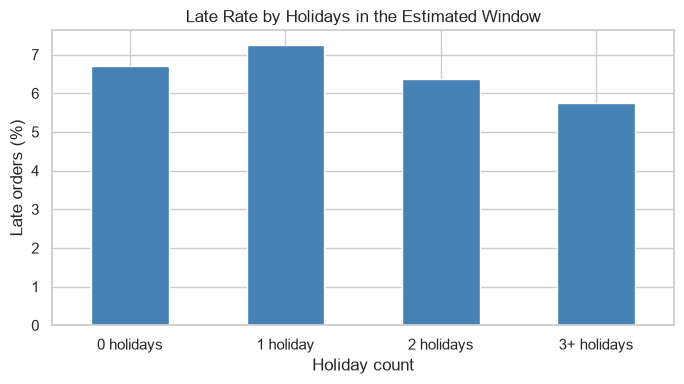

Excluded missing values: 0


In [9]:
# Purpose: Compare late rates by holiday count in the estimated window.

column = "national_holiday_count_in_estimated_window"

holiday_window = labelled.loc[
    labelled[column].notna()
].copy()

holiday_window["holiday_group"] = (
    holiday_window[column]
    .clip(upper=3)
    .astype(int)
    .map({
        0: "0 holidays",
        1: "1 holiday",
        2: "2 holidays",
        3: "3+ holidays"
    })
)

window_summary = (
    holiday_window.groupby("holiday_group")
    .agg(
        valid_orders=("is_late", "size"),
        late_orders=("is_late", "sum")
    )
    .reindex([
        "0 holidays", "1 holiday", "2 holidays", "3+ holidays"
    ])
)

window_summary["late_rate_percent"] = (
    window_summary["late_orders"]
    / window_summary["valid_orders"] * 100
)

display(window_summary.round(2))

window_summary["late_rate_percent"].plot(
    kind="bar",
    color="steelblue",
    figsize=(7, 4),
    rot=0
)

plt.title("Late Rate by Holidays in the Estimated Window")
plt.xlabel("Holiday count")
plt.ylabel("Late orders (%)")
plt.tight_layout()
save_figure(plt.gcf(), "vis04_holiday_window.png")
plt.show()

print("Excluded missing values:", labelled[column].isna().sum())
save_table(window_summary, "vis04_holiday_window.csv")


items_value                freight_value                \
                     count    mean median         count   mean median   
delivery_label                                                          
Not Late             89936  136.03  85.39         89936  22.61  17.06   
Late                  6534  150.89  90.05          6534  25.25  18.23   

               total_product_weight_g                  \
                                count     mean median   
delivery_label                                          
Not Late                        89914  2361.68  750.0   
Late                             6534  2735.64  817.0   

               total_product_volume_cm3                    
                                  count      mean  median  
delivery_label                                             
Not Late                          89920  17208.60  7200.0  
Late                               6534  19029.33  7629.0

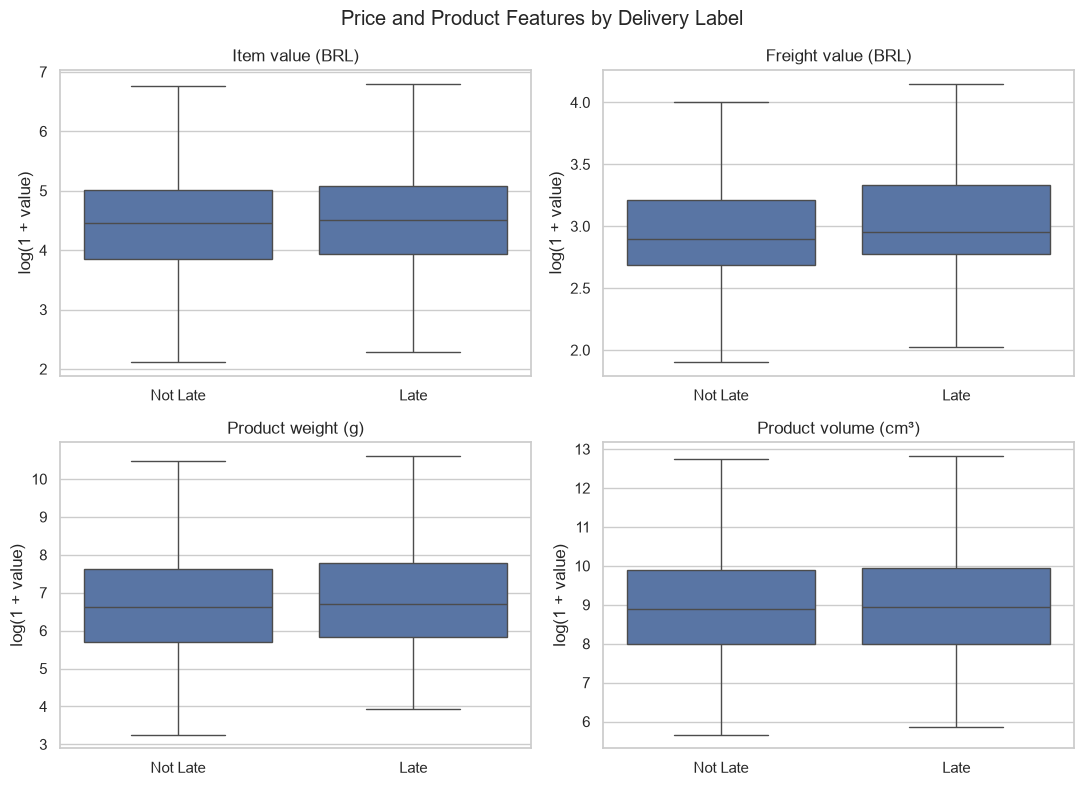

In [10]:
# Purpose: Compare price and product features by delivery label.

import numpy as np

features = {
    "items_value": "Item value (BRL)",
    "freight_value": "Freight value (BRL)",
    "total_product_weight_g": "Product weight (g)",
    "total_product_volume_cm3": "Product volume (cm³)"
}

price_product_summary = (
    labelled.groupby("delivery_label")[list(features)]
    .agg(["count", "mean", "median"])
    .reindex(["Not Late", "Late"])
)

display(price_product_summary.round(2))

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (column, title) in zip(axes.flat, features.items()):

    plot_data = labelled[
        ["delivery_label", column]
    ].dropna().copy()

    assert plot_data[column].ge(0).all()

    plot_data["log_value"] = np.log1p(plot_data[column])

    sns.boxplot(
        data=plot_data,
        x="delivery_label",
        y="log_value",
        order=["Not Late", "Late"],
        showfliers=False,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("log(1 + value)")

plt.suptitle("Price and Product Features by Delivery Label")
plt.tight_layout()
save_figure(plt.gcf(), "vis05_price_product_boxplots.png")
plt.show()
save_table(price_product_summary, "vis05_price_product_summary.csv")


In [11]:
# Purpose: Summarise destination weather by delivery label.

weather_features = {
    "destination_rain_state_mean_mm": "Rainfall (mm)",
    "destination_air_temp_state_mean_c": "Air temperature (°C)",
    "destination_humidity_state_mean_pct": "Humidity (%)",
    "destination_wind_speed_sample_state_mean_ms": "Wind speed (m/s)"
}

for column, title in weather_features.items():

    print(title)

    summary = (
        labelled.groupby("delivery_label")[column]
        .agg(
            valid_orders="count",
            mean="mean",
            median="median"
        )
        .reindex(["Not Late", "Late"])
    )

    total = labelled.groupby("delivery_label").size()

    summary["missing_orders"] = total - summary["valid_orders"]

    display(summary.round(2))
    save_table(summary, f"vis06_destination_{column}_summary.csv")

Rainfall (mm)


,valid_orders,mean,median,missing_orders
delivery_label,,,,
Not Late,89079,3.53,0.81,857
Late,6465,4.85,2.22,69


Air temperature (°C)


,valid_orders,mean,median,missing_orders
delivery_label,,,,
Not Late,89386,21.61,21.91,550
Late,6498,22.82,23.22,36


Humidity (%)


,valid_orders,mean,median,missing_orders
delivery_label,,,,
Not Late,89213,72.97,73.84,723
Late,6487,75.72,76.95,47


Wind speed (m/s)


,valid_orders,mean,median,missing_orders
delivery_label,,,,
Not Late,89321,1.86,1.76,615
Late,6497,1.87,1.77,37


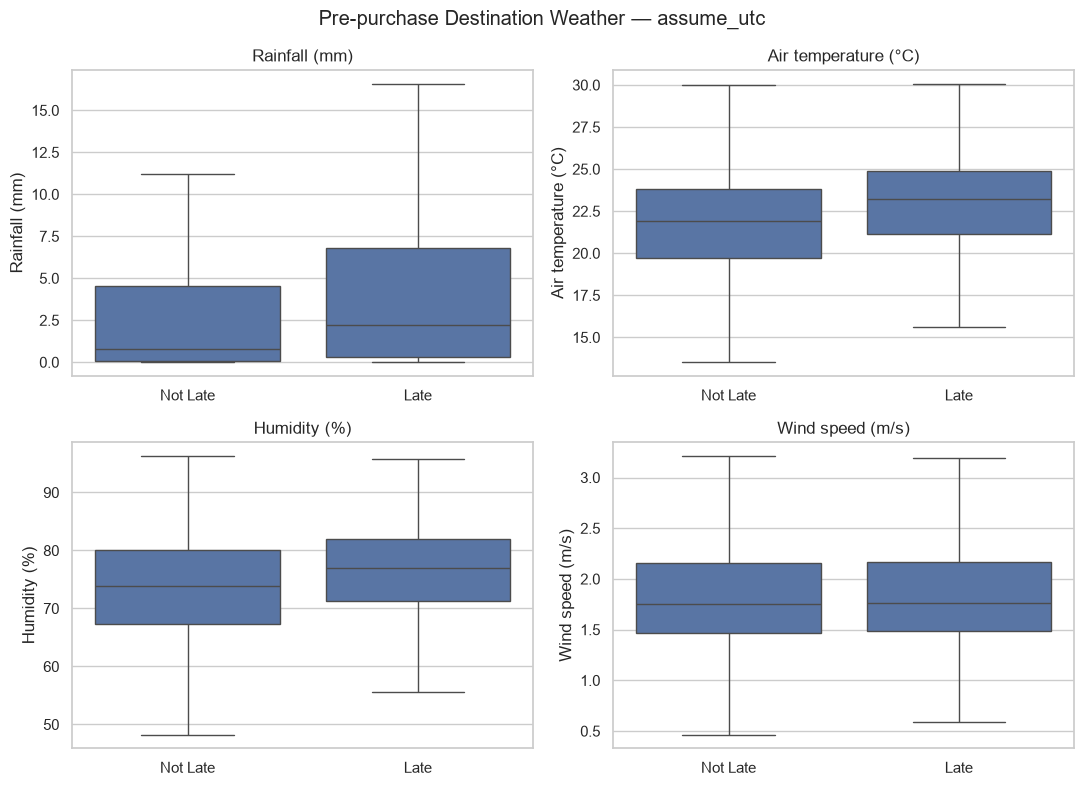

In [12]:
# Purpose: Display destination weather distributions by delivery label.

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (column, title) in zip(
    axes.flat, weather_features.items()
):

    plot_data = labelled[
        ["delivery_label", column]
    ].dropna()

    sns.boxplot(
        data=plot_data,
        x="delivery_label",
        y=column,
        order=["Not Late", "Late"],
        showfliers=False,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(title)

plt.suptitle(f"Pre-purchase Destination Weather — {SCENARIO}")
plt.tight_layout()
save_figure(plt.gcf(), "vis06_destination_weather_boxplots.png")
plt.show()

In [13]:
# Purpose: Summarise origin weather by delivery label.

seller_weather_features = {
    "origin_rain_state_mean_mm": "Seller rainfall (mm)",
    "origin_air_temp_state_mean_c": "Seller air temperature (°C)",
    "origin_humidity_state_mean_pct": "Seller humidity (%)",
    "origin_wind_speed_sample_state_mean_ms": "Seller wind speed (m/s)"
}

for column, title in seller_weather_features.items():

    print(title)

    summary = (
        labelled.groupby("delivery_label")[column]
        .agg(
            valid_orders="count",
            mean="mean",
            median="median"
        )
        .reindex(["Not Late", "Late"])
    )

    total = labelled.groupby("delivery_label").size()

    summary["missing_orders"] = total - summary["valid_orders"]

    display(summary.round(2))
    save_table(summary, f"vis07_origin_{column}_summary.csv")

Seller rainfall (mm)


,valid_orders,mean,median,missing_orders
delivery_label,,,,
Not Late,89784,3.55,0.81,152
Late,6527,4.66,2.30,7


Seller air temperature (°C)


,valid_orders,mean,median,missing_orders
delivery_label,,,,
Not Late,89802,21.20,21.54,134
Late,6530,22.36,22.83,4


Seller humidity (%)


,valid_orders,mean,median,missing_orders
delivery_label,,,,
Not Late,89788,72.64,73.33,148
Late,6529,74.85,76.07,5


Seller wind speed (m/s)


,valid_orders,mean,median,missing_orders
delivery_label,,,,
Not Late,89799,1.76,1.69,137
Late,6529,1.67,1.61,5


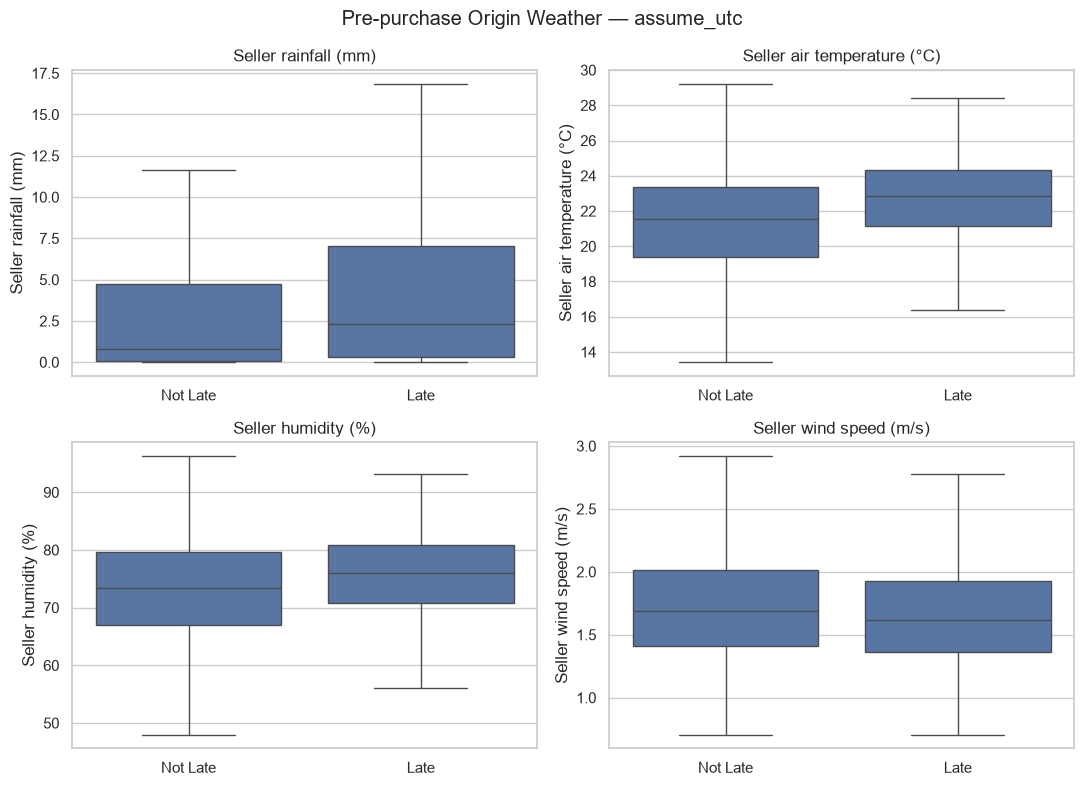

In [14]:
# Purpose: Compare origin weather distributions by delivery label.

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (column, title) in zip(
    axes.flat, seller_weather_features.items()
):

    plot_data = labelled[
        ["delivery_label", column]
    ].dropna()

    sns.boxplot(
        data=plot_data,
        x="delivery_label",
        y=column,
        order=["Not Late", "Late"],
        showfliers=False,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(title)

plt.suptitle(f"Pre-purchase Origin Weather — {SCENARIO}")
plt.tight_layout()
save_figure(plt.gcf(), "vis07_origin_weather_boxplots.png")
plt.show()

,valid_orders,late_orders,rainfall_min_mm,rainfall_max_mm,late_rate_percent
rain_group,,,,,
"(-0.001, 0.0647]",23954,1017.0,0.00,0.06,4.25
"(0.0647, 0.889]",23831,1339.0,0.06,0.89,5.62
"(0.889, 4.709]",23874,1915.0,0.89,4.71,8.02
"(4.709, 78.2]",23885,2194.0,4.71,78.20,9.19


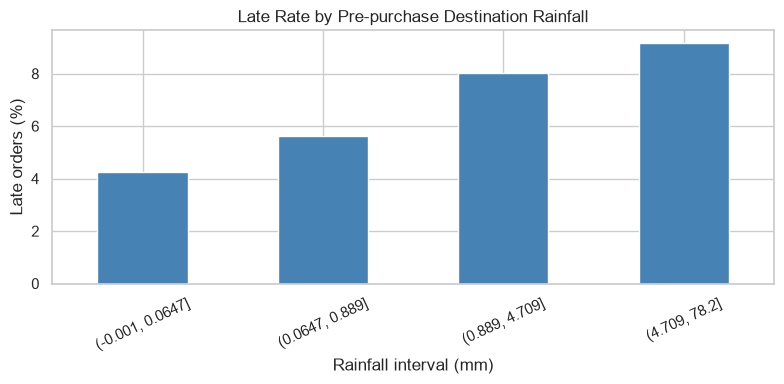

Excluded missing rainfall: 926


In [15]:
# Purpose: Compare late rates across destination rainfall groups.

column = "destination_rain_state_mean_mm"

rain_data = labelled.loc[
    labelled[column].notna(),
    ["is_late", column]
].copy()

rain_data["rain_group"] = pd.qcut(
    rain_data[column],
    q=4,
    duplicates="drop"
)

rain_summary = (
    rain_data.groupby("rain_group", observed=True)
    .agg(
        valid_orders=("is_late", "size"),
        late_orders=("is_late", "sum"),
        rainfall_min_mm=(column, "min"),
        rainfall_max_mm=(column, "max")
    )
)

rain_summary["late_rate_percent"] = (
    rain_summary["late_orders"]
    / rain_summary["valid_orders"] * 100
)

display(rain_summary.round(2))

rain_summary["late_rate_percent"].plot(
    kind="bar",
    color="steelblue",
    figsize=(8, 4),
    rot=25
)

plt.title("Late Rate by Pre-purchase Destination Rainfall")
plt.xlabel("Rainfall interval (mm)")
plt.ylabel("Late orders (%)")
plt.tight_layout()
save_figure(plt.gcf(), "vis08_destination_rainfall_groups.png")
plt.show()

print("Excluded missing rainfall:", labelled[column].isna().sum())
save_table(rain_summary, "vis08_destination_rainfall_groups.csv")


Air temperature (°C)


,valid_orders,late_orders,value_min,value_max,late_rate_percent
weather_group,,,,,
"(4.013999999999999, 19.783]",23971,954.0,4.02,19.78,3.98
"(19.783, 22.021]",24022,1264.0,19.78,22.02,5.26
"(22.021, 23.932]",24033,1685.0,22.02,23.93,7.01
"(23.932, 31.709]",23858,2595.0,23.93,31.71,10.88


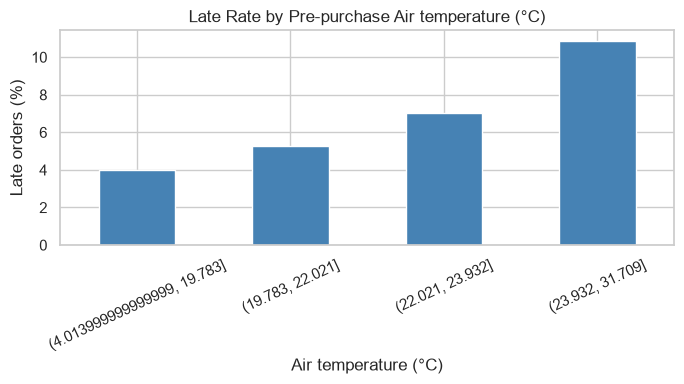

Excluded missing values: 586
Humidity (%)


,valid_orders,late_orders,value_min,value_max,late_rate_percent
weather_group,,,,,
"(26.081999999999997, 67.738]",23935,1000.0,26.08,67.74,4.18
"(67.738, 74.094]",23930,1348.0,67.74,74.09,5.63
"(74.094, 80.306]",23923,2032.0,74.09,80.31,8.49
"(80.306, 96.284]",23912,2107.0,80.31,96.28,8.81


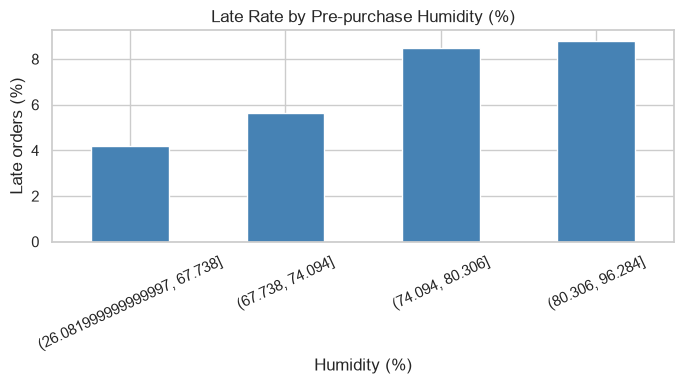

Excluded missing values: 770
Wind speed (m/s)


,valid_orders,late_orders,value_min,value_max,late_rate_percent
weather_group,,,,,
"(0.465, 1.466]",23955,1539.0,0.47,1.47,6.42
"(1.466, 1.757]",24048,1675.0,1.47,1.76,6.97
"(1.757, 2.162]",23880,1642.0,1.76,2.16,6.88
"(2.162, 5.784]",23935,1641.0,2.16,5.78,6.86


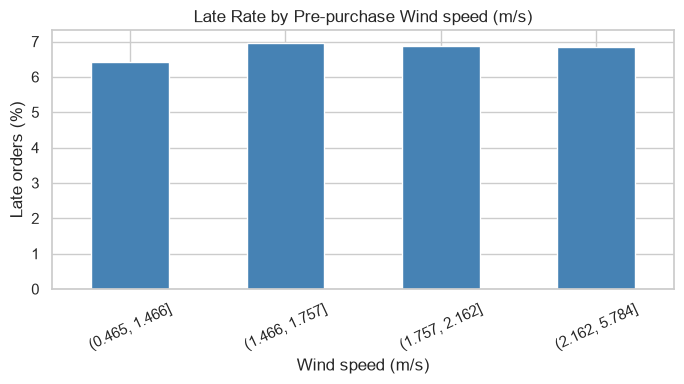

Excluded missing values: 652


In [16]:
# Purpose: Compare late rates across destination weather groups.

weather_columns = {
    "destination_air_temp_state_mean_c": "Air temperature (°C)",
    "destination_humidity_state_mean_pct": "Humidity (%)",
    "destination_wind_speed_sample_state_mean_ms": "Wind speed (m/s)"
}

for column, title in weather_columns.items():

    weather_data = labelled.loc[
        labelled[column].notna(),
        ["is_late", column]
    ].copy()

    weather_data["weather_group"] = pd.qcut(
        weather_data[column],
        q=4,
        duplicates="drop"
    )

    weather_summary = (
        weather_data.groupby("weather_group", observed=True)
        .agg(
            valid_orders=("is_late", "size"),
            late_orders=("is_late", "sum"),
            value_min=(column, "min"),
            value_max=(column, "max")
        )
    )

    weather_summary["late_rate_percent"] = (
        weather_summary["late_orders"]
        / weather_summary["valid_orders"] * 100
    )

    print(title)
    display(weather_summary.round(2))
    save_table(weather_summary, f"vis09_{column}_groups.csv")

    weather_summary["late_rate_percent"].plot(
        kind="bar",
        color="steelblue",
        figsize=(7, 4),
        rot=25
    )

    plt.title(f"Late Rate by Pre-purchase {title}")
    plt.xlabel(title)
    plt.ylabel("Late orders (%)")
    plt.tight_layout()
    save_figure(plt.gcf(), f"vis09_{column}_groups.png")
    plt.show()

    print("Excluded missing values:", labelled[column].isna().sum())

,valid_orders,late_orders,rain_orders,mean_rainfall_mm,temperature_orders,mean_temperature_c,late_rate_percent
month,,,,,,,
2016-09,1,1.0,1,0.39,1,22.61,100.00
2016-10,265,2.0,261,3.98,261,20.35,0.75
2016-12,1,0.0,1,2.72,1,22.23,0.00
2017-01,750,22.0,740,7.16,742,24.03,2.93
2017-02,1653,49.0,1618,4.53,1621,24.74,2.96
2017-03,2546,116.0,2512,4.78,2513,23.75,4.56
2017-04,2303,151.0,2267,3.84,2292,22.20,6.56
2017-05,3545,106.0,3515,4.18,3516,20.62,2.99
2017-06,3135,95.0,3100,2.60,3111,19.11,3.03


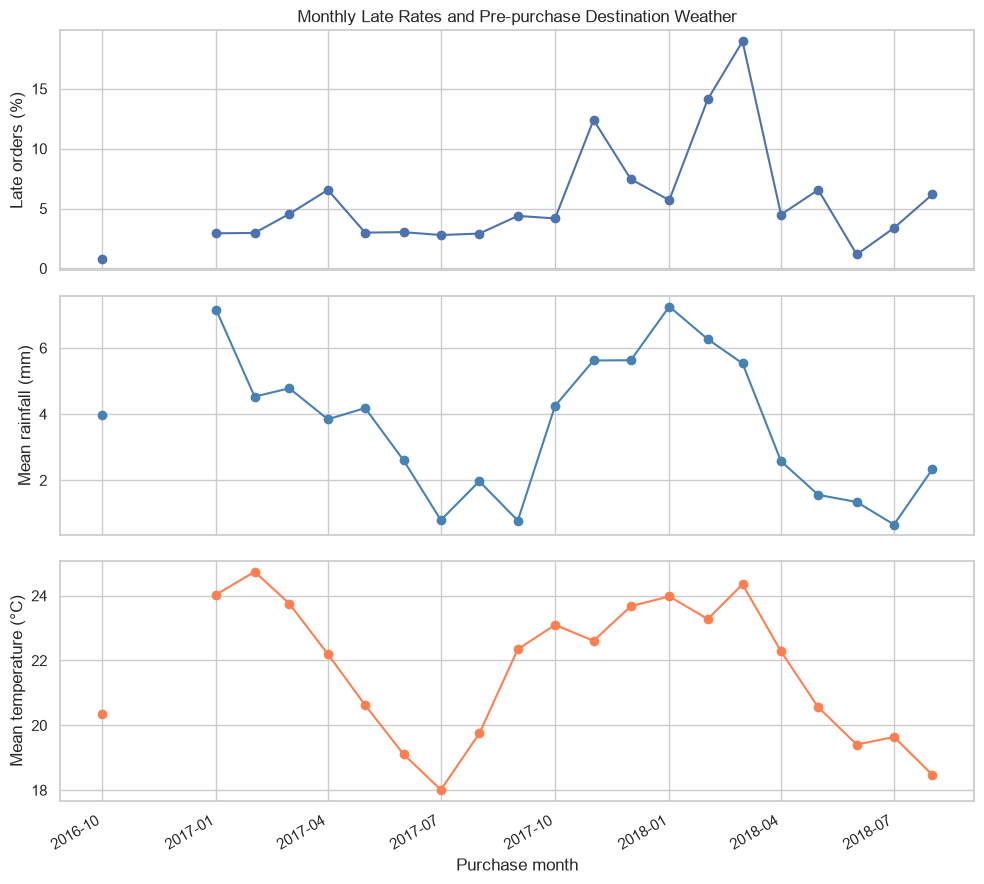

In [17]:
# Purpose: Display monthly late rates and destination weather.

monthly_data = labelled.copy()

monthly_data["month"] = pd.to_datetime(
    monthly_data["order_purchase_timestamp"],
    errors="raise"
).dt.to_period("M")

monthly_summary = monthly_data.groupby("month").agg(
    valid_orders=("is_late", "size"),
    late_orders=("is_late", "sum"),

    rain_orders=("destination_rain_state_mean_mm", "count"),
    mean_rainfall_mm=("destination_rain_state_mean_mm", "mean"),

    temperature_orders=("destination_air_temp_state_mean_c", "count"),
    mean_temperature_c=("destination_air_temp_state_mean_c", "mean")
)

monthly_summary["late_rate_percent"] = (
    monthly_summary["late_orders"]
    / monthly_summary["valid_orders"] * 100
)

display(monthly_summary.round(2))

# Show all months and leave gaps where no eligible values exist.
all_months = pd.period_range(
    monthly_summary.index.min(),
    monthly_summary.index.max(),
    freq="M"
)

plot_data = monthly_summary.reindex(all_months).copy()

# Hide sparse months in the charts, but retain them in the table.
plot_data.loc[
    plot_data["valid_orders"].fillna(0) < 100,
    "late_rate_percent"
] = float("nan")

plot_data.loc[
    plot_data["rain_orders"].fillna(0) < 100,
    "mean_rainfall_mm"
] = float("nan")

plot_data.loc[
    plot_data["temperature_orders"].fillna(0) < 100,
    "mean_temperature_c"
] = float("nan")

dates = plot_data.index.to_timestamp()

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(dates, plot_data["late_rate_percent"], marker="o")
axes[0].set_ylabel("Late orders (%)")
axes[0].set_title("Monthly Late Rates and Pre-purchase Destination Weather")

axes[1].plot(
    dates,
    plot_data["mean_rainfall_mm"],
    marker="o",
    color="steelblue"
)
axes[1].set_ylabel("Mean rainfall (mm)")

axes[2].plot(
    dates,
    plot_data["mean_temperature_c"],
    marker="o",
    color="coral"
)
axes[2].set_ylabel("Mean temperature (°C)")
axes[2].set_xlabel("Purchase month")

fig.autofmt_xdate()
plt.tight_layout()
save_figure(plt.gcf(), "vis10_monthly_weather.png")
plt.show()
save_table(monthly_summary, "vis10_monthly_weather_summary.csv")
save_table(plot_data, "vis10_monthly_chart_data.csv")


In [18]:
# Purpose: Compare destination weather between delivery labels within each state.

weather_features = {
    "destination_rain_state_mean_mm": "Rainfall (mm)",
    "destination_air_temp_state_mean_c": "Temperature (C)",
    "destination_humidity_state_mean_pct": "Humidity (%)",
    "destination_wind_speed_sample_state_mean_ms": "Wind speed (m/s)",
}

state_weather_comparison = (
    labelled.groupby(["customer_state", "delivery_label"])[
        list(weather_features)
    ]
    .agg(["count", "mean", "median"])
)

display(state_weather_comparison.round(2))
save_table(state_weather_comparison, "vis11_state_weather_summary.csv")


destination_rain_state_mean_mm                \
                                                       count   mean median   
customer_state delivery_label                                                
AC             Late                                        2   4.20   4.20   
               Not Late                                   30   5.94   3.06   
AL             Late                                       77   3.70   0.55   
               Not Late                                  285   3.94   0.88   
AM             Late                                        1  11.19  11.19   
               Not Late                                  110   6.82   5.11   
AP             Late                                        2  23.45  23.45   
               Not Late                                   34   6.12   0.47   
BA             Late                                      396   2.55   1.64   
               Not Late                                 2860   2.24   1.32   
CE             Late                                      176   4.33   2.67   
               Not Late                                 1103   2.04   0.16   
DF             Late                                       99   4.54   1.00   
               Not Late                                 1663   3.30   0.00   
ES             Late                                      212   4.82   1.20   
               Not Late                                 1754   3.60   0.84   
GO             Late                                      128   5.42   3.47   
               Not Late                                 1829   3.52   0.36   
MA             Late                                      122   5.25   1.85   
               Not Late                                  581   4.08   1.07   
MG             Late                                      519   5.17   3.52   
               Not Late                                10835   3.17   0.81   
MS             Late                                       60   4.23   3.10   
               Not Late                                  530   2.89   0.23   
MT             Late                                       51   6.84   4.98   
               Not Late                                  817   4.09   2.03   
PA             Late                                      104   7.22   5.56   
               Not Late                                  837   5.54   2.98   
PB             Late                                       47   3.23   0.62   
               Not Late                                  393   2.11   0.35   
PE             Late                                      153   1.96   0.93   
               Not Late                                 1440   2.05   0.73   
PI             Late                                       66   3.67   1.55   
               Not Late                                  410   2.33   0.20   
PR             Late                                      199   5.46   1.44   
               Not Late                                 4724   4.29   0.67   
RJ             Late                                     1495   6.34   2.65   
               Not Late                                10855   3.71   0.74   
RN             Late                                       37   3.06   0.09   
               Not Late                                  365   2.34   0.12   
RO             Late                                        4   2.98   3.12   
               Not Late                                  130   5.95   3.60   
RR             Late                                        2  14.20  14.20   
               Not Late                                   20   5.87   0.20   
RS             Late                                      325   4.69   0.97   
               Not Late                                 5019   4.39   0.79   
SC             Late                                      291   4.57   1.67   
               Not Late                                 3255   4.25   1.09   
SE             Late                                 

### Within-state weather comparison

Late orders had higher mean pre-purchase rainfall than non-late
orders in several states, including RJ, MG, CE, and SP. However,
the direction and size of the differences varied across states.

Temperature and humidity also differed between delivery groups
in some states, while mean wind speed differences were often small.

These descriptive comparisons do not establish causality or
statistical significance. Purchase month, order characteristics,
missing weather values, and shared state-day weather observations
should be considered in further analysis.

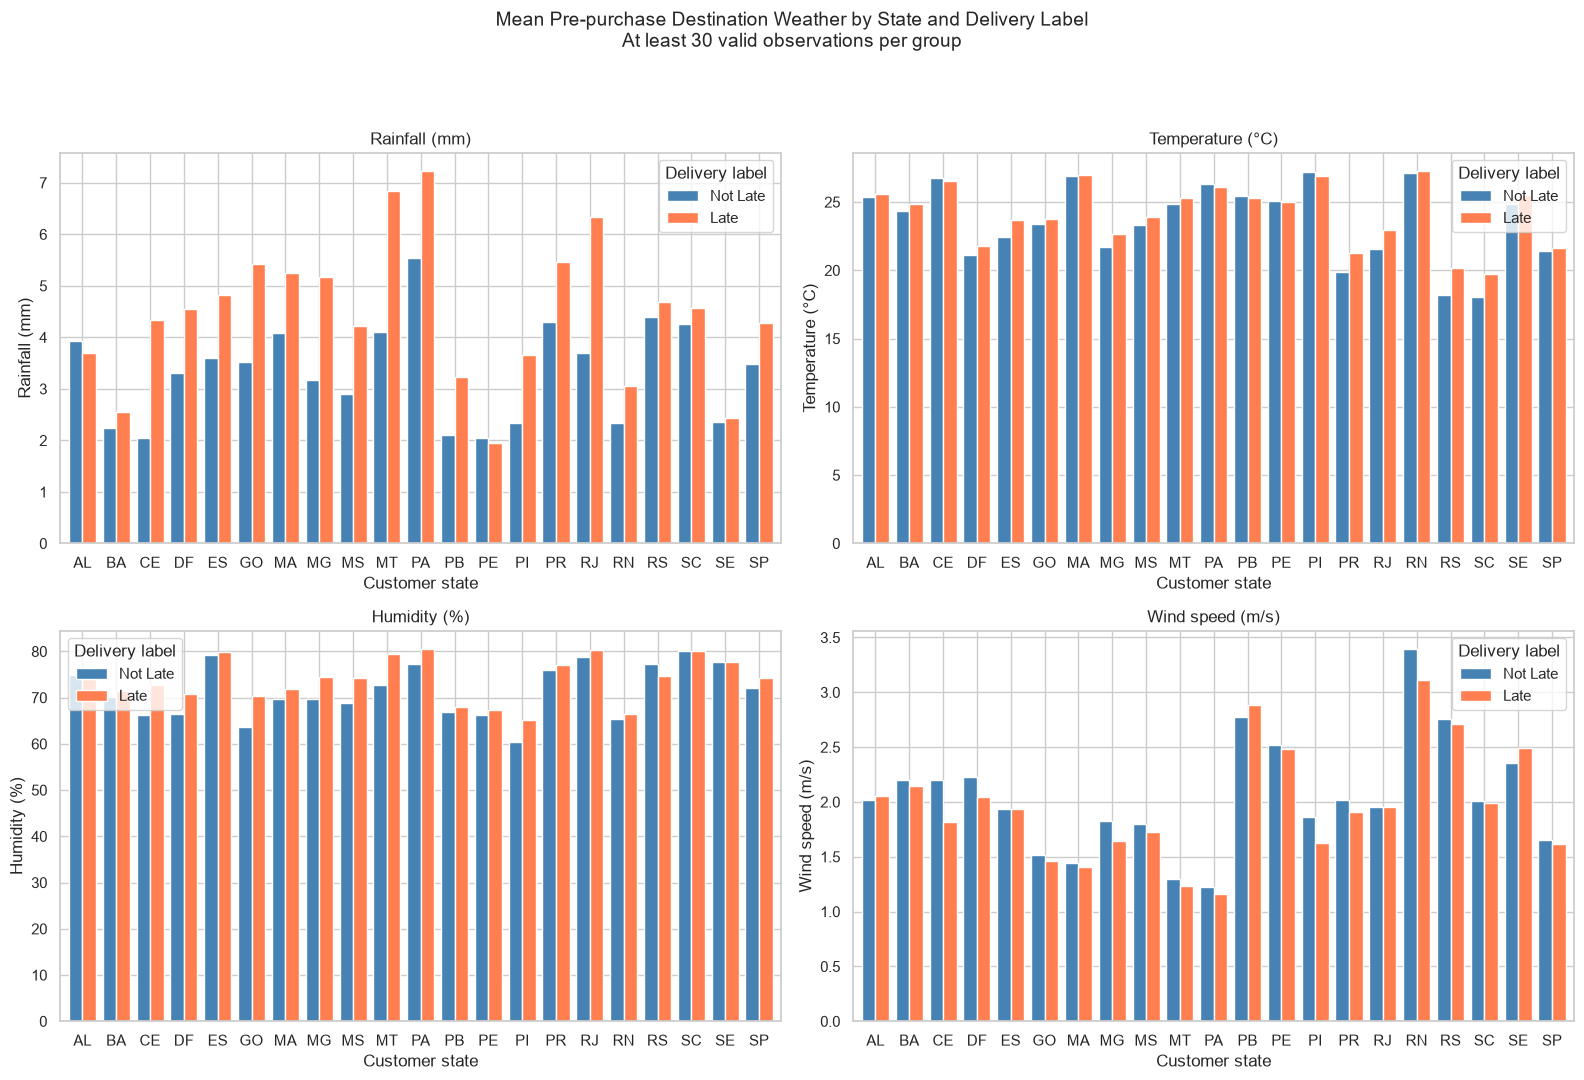

In [19]:
# Purpose: Compare mean destination weather by delivery label within states.

weather_features = {
    "destination_rain_state_mean_mm": "Rainfall (mm)",
    "destination_air_temp_state_mean_c": "Temperature (°C)",
    "destination_humidity_state_mean_pct": "Humidity (%)",
    "destination_wind_speed_sample_state_mean_ms": "Wind speed (m/s)",
}

MIN_GROUP_SIZE = 30
label_order = ["Not Late", "Late"]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, (feature, title) in zip(axes.flat, weather_features.items()):
    summary = (
        labelled.groupby(["customer_state", "delivery_label"])[feature]
        .agg(["count", "mean"])
        .reset_index()
    )

    save_table(summary, f"vis12_{feature}_state_groups.csv", False)

    counts = summary.pivot(
        index="customer_state",
        columns="delivery_label",
        values="count",
    ).reindex(columns=label_order, fill_value=0).fillna(0)

    valid_states = counts.index[
        counts.ge(MIN_GROUP_SIZE).all(axis=1)
    ]

    means = (
        summary.pivot(
            index="customer_state",
            columns="delivery_label",
            values="mean",
        )
        .reindex(index=valid_states, columns=label_order)
        .sort_index()
    )

    save_table(means, f"vis12_{feature}_displayed_means.csv")

    if means.empty:
        ax.set_title(title)
        ax.text(
            0.5, 0.5, "No states meet the sample size rule",
            ha="center", va="center", transform=ax.transAxes,
        )
        continue

    means.plot.bar(
        ax=ax,
        color=["steelblue", "coral"],
        width=0.8,
        rot=0,
    )

    ax.set_title(title)
    ax.set_xlabel("Customer state")
    ax.set_ylabel(title)
    ax.legend(title="Delivery label")

fig.suptitle(
    "Mean Pre-purchase Destination Weather by State and Delivery Label\n"
    f"At least {MIN_GROUP_SIZE} valid observations per group",
    fontsize=14,
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
save_figure(plt.gcf(), "vis12_state_weather_comparison.png")
plt.show()

## Conclusion: Pre-purchase Weather and Late Delivery

The descriptive analysis shows that late orders had higher mean
pre-purchase rainfall and humidity than non-late orders in many
customer states. However, this pattern was not consistent across
all states.

Temperature differences varied by state, while mean wind speed
differences were generally small. Monthly comparisons also showed
that peaks in late delivery rates did not always match peaks in
rainfall or temperature.

These findings suggest that rainfall and humidity deserve further
investigation as potential predictors. They do not establish that
weather causes delivery delays or improves prediction performance.

### Limitations and Next Steps

- Weather represents state-level conditions before purchase, not
  conditions along the delivery route or during transportation.
- Purchase month and order characteristics may explain part of
  the observed differences.
- Multiple orders can share the same state-day weather values.
- The minimum of 30 valid observations per group is a display rule,
  not evidence of statistical significance.
- Further analysis should adjust for time, location, and order
  characteristics, and compare models with and without weather
  features using the same temporal evaluation protocol.

In [20]:
# Purpose: List the CSV tables and PNG figures created for this scenario.
exported_files = []
for folder, pattern, kind in [
    (TABLE_DIR, "*.csv", "table"),
    (FIGURE_DIR, "*.png", "figure"),
]:
    for path in sorted(folder.glob(pattern)):
        exported_files.append({"type": kind, "filename": path.name, "bytes": path.stat().st_size})
export_summary = pd.DataFrame(exported_files)
display(export_summary)
print("Table folder:", TABLE_DIR)
print("Figure folder:", FIGURE_DIR)
print("Exported files:", len(export_summary))


,type,filename,bytes
0,table,vis00_detailed_sample_summary.csv,104
1,table,vis00_sample_summary.csv,92
2,table,vis01_delivery_labels.csv,95
3,table,vis01_label_distribution_detail.csv,98
4,table,vis02_missing_features.csv,1727
5,table,vis03_purchase_holiday.csv,157
6,table,vis04_holiday_window.csv,230
7,table,vis05_price_product_summary.csv,573
8,table,vis06_destination_destination_air_temp_state_m...,167
9,table,vis06_destination_destination_humidity_state_m...,164


Table folder: c:\Users\LENOVO\OneDrive\Desktop\PTTK\Group5_STAT3013.R11\outputs\tables\enriched_eda\assume_utc
Figure folder: c:\Users\LENOVO\OneDrive\Desktop\PTTK\Group5_STAT3013.R11\outputs\figures\enriched_eda\assume_utc
Exported files: 45
